In [ ]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(0)

def softmax(Z):
    Z = Z - np.max(Z, axis=1, keepdims=True)
    E_z = np.exp(Z)
    return E_z / np.sum(E_z, axis=1, keepdims=True)


def train(X, labels, K, lr=0.1, epochs=500):
    m, i = X.shape
    W = np.zeros((K, i))
    b = np.zeros(K)
    Y = np.eye(K)[labels]       
    ##eye는 K X K 행렬이고 Lables에 있는 정수는 행마다 one hot
    #encoding의 위치를 출력 (m, K) one-hot

    history = []

    for ep in range(epochs):
        # forward (루프 안!)
        Z = X @ W.T + b            # (m, K)
        P = softmax(Z)             # (m, K)

        # loss
        loss = -np.sum(Y * np.log(P + 1e-12)) / m
        history.append(loss)

        # backward
        # backward is always same in GLM
        dW = (P - Y).T @ X / m     # (K, i)
        db = (P - Y).mean(axis=0)  # (K,)
        assert dW.shape == W.shape and db.shape == b.shape

        # update
        W = W - lr * dW
        b = b - lr * db

    return W, b, history

def train_batch(X,batch_size, labels, K, lr=0.1, epochs=500,seed = 42):

    m, i = X.shape
    W = np.zeros((K, i))
    b = np.zeros(K)
    Y = np.eye(K)[labels]
    rng = np.random.default_rng(seed)

    history = []

    for epoch in range(epochs):

        idx = rng.permutation(m)

        for start in range(0,m,batch_size):

            batch = idx[start:start+batch_size]

            Xb = X[batch] #(B,i)
            Yb = Y[batch] #(B,K)
            
            B= len(batch)

            P = softmax(Xb @ W.T + b)             # (B, K)
            
            # backward
            # backward is always same in GLM
            dW = (P - Yb).T @ Xb / B     # (K, i)
            db = (P - Yb).mean(axis=0)  # (K,)
            assert dW.shape == W.shape and db.shape == b.shape

            #update
            W = W - lr * dW
            b = b - lr * db
            
        P_all = softmax(X @ W.T + b)
        history.append(-np.sum(Y * np.log(P_all + 1e-12)) / m)

    return W, b, history

def evaluate(X_test,labels_test,W,b):

    m = X_test.shape[0]
    Z =  X_test @ W.T + b
    P = softmax(Z)

    loss = -np.mean(np.log(P[np.arange(m), labels_test] + 1e-12))
    
    pred = P.argmax(axis=1)                        # (m,)
    acc = (pred == labels_test).mean()             # True/False의 평균 = 정답 비율

    return loss, acc

In [7]:
from sklearn.datasets import fetch_openml

mnist = fetch_openml("mnist_784",version = 1,as_frame=False)

X = mnist.data / 255.0                  # (70000, 784), 0~1 스케일
labels = mnist.target.astype(int)       # K = 10

X_train, X_test = X[:60000], X[60000:]
y_train, y_test = labels[:60000], labels[60000:]
K = len(np.unique(labels))     # 10
print(X_train.shape, X_test.shape)      # (60000, 784) (10000, 784)
print(K)



(60000, 784) (10000, 784)
10


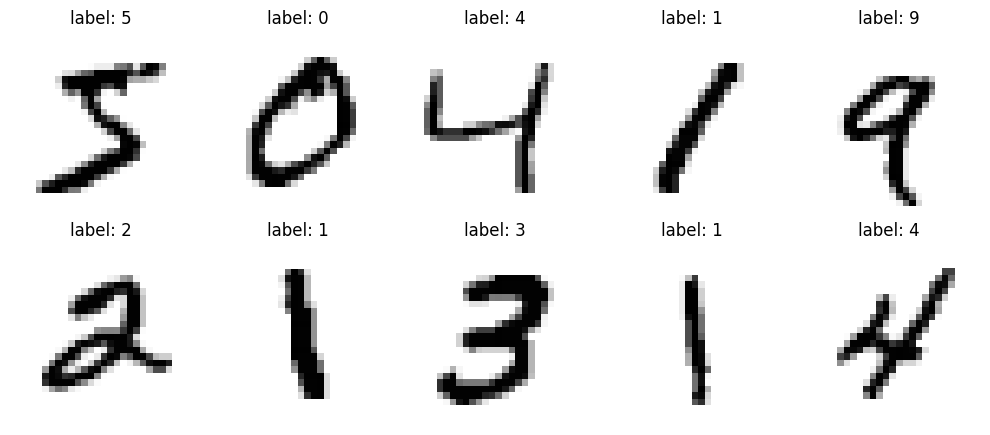

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))
for ax, n in zip(axes.ravel(), range(10)):
    #image 보는 방법
    ax.imshow(X_train[n].reshape(28, 28), cmap="gray_r")   # 784 -> 28x28 복원
    #title 붙여서 보기
    ax.set_title(f"label: {y_train[n]}")
    ax.axis("off")
plt.tight_layout()
plt.show()

걸린 시간: 27.1초
train loss 0.250 acc 0.9309 | test loss 0.273 acc 0.9241


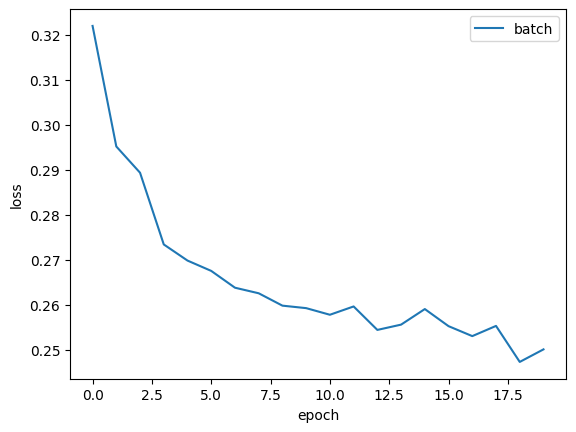

In [9]:
import time

t = time.time()
W, b, hist = train_batch(X_train, batch_size=128, labels=y_train, K=K, lr=0.5, epochs=20)
print(f"걸린 시간: {time.time() - t:.1f}초")

tr = evaluate(X_train, y_train, W, b)
te = evaluate(X_test, y_test, W, b)
print(f"train loss {tr[0]:.3f} acc {tr[1]:.4f} | test loss {te[0]:.3f} acc {te[1]:.4f}")


plt.plot(hist, label="batch");
plt.xlabel("epoch"); plt.ylabel("loss"); plt.legend(); plt.show()

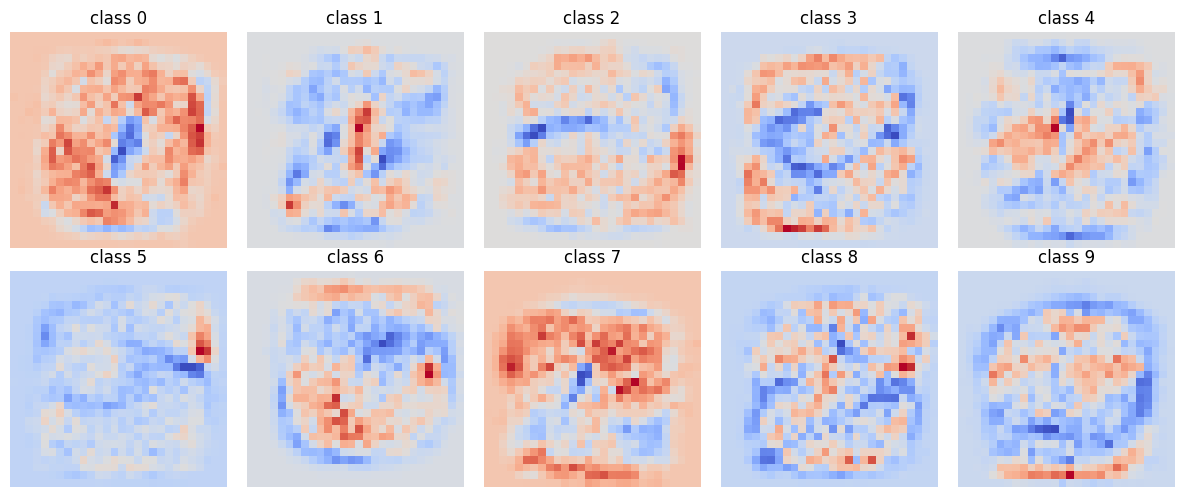

In [10]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for j, ax in enumerate(axes.ravel()):
    ax.imshow(W[j].reshape(28, 28), cmap="coolwarm")
    ax.set_title(f"class {j}")
    ax.axis("off")
plt.tight_layout(); plt.show()

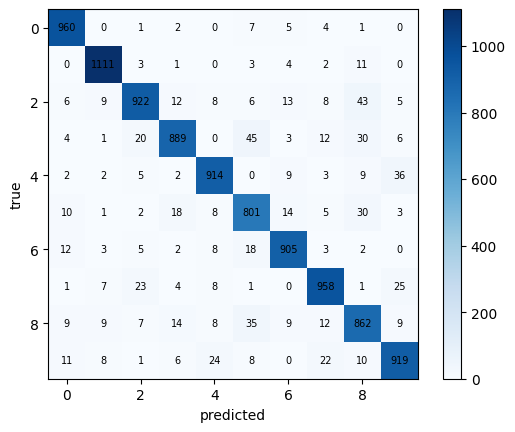

In [ ]:
pred = softmax(X_test @ W.T + b).argmax(axis=1)
C = np.zeros((K, K), dtype=int)
np.add.at(C, (y_test, pred), 1)          

plt.imshow(C, cmap="Blues"); plt.colorbar()
plt.xlabel("predicted"); plt.ylabel("true")
for r in range(K):
    for c in range(K):
        plt.text(c, r, C[r, c], ha="center", va="center", fontsize=7)
plt.show()